In [1]:
!pwd

/Users/zagidull/Desktop/synosys/lina-s paper


In [2]:
import numpy as np
import pandas as pd
import os
import scipy.stats
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


os.chdir('/Users/zagidull/Desktop/synosys/lina-s paper/')

In [3]:
df = pd.read_csv('data/SynoSys_27.02.2026-15.04.2026.csv/bbi-(enhanced).csv')
print(df.shape)
df.head()

(6576006, 17)


,User Id,User First Name,User Last Name,User Email,Team Names,Group Names,Calendar Date (Local),Start Time (Local),Time Zone (Local),Calendar Date (UTC),Start Time (UTC),Start Time (ms),Time Zone (s),BBI (ms),Gap Duration (ms),Status,BBI Type
0,69aa9a01c272d7436ea5db59,Paultest,NaN,3aa9b47e@nomail.local,NaN,SynoSys,2026-03-06,2026-03-06T10:24:12.000,100,2026-03-06,2026-03-06T09:24:12.000,1772789052000,3600,1007,NaN,LOW_CONFIDENCE,Enhanced BBI
1,69aa9a01c272d7436ea5db59,Paultest,NaN,3aa9b47e@nomail.local,NaN,SynoSys,2026-03-06,2026-03-06T10:24:13.508,100,2026-03-06,2026-03-06T09:24:13.508,1772789053508,3600,1507,NaN,LOW_CONFIDENCE,Enhanced BBI
2,69aa9a01c272d7436ea5db59,Paultest,NaN,3aa9b47e@nomail.local,NaN,SynoSys,2026-03-06,2026-03-06T10:24:14.131,100,2026-03-06,2026-03-06T09:24:14.131,1772789054131,3600,625,NaN,LOW_CONFIDENCE,Enhanced BBI
3,69aa9a01c272d7436ea5db59,Paultest,NaN,3aa9b47e@nomail.local,NaN,SynoSys,2026-03-06,2026-03-06T10:24:14.818,100,2026-03-06,2026-03-06T09:24:14.818,1772789054818,3600,687,NaN,LOW_CONFIDENCE,Enhanced BBI
4,69aa9a01c272d7436ea5db59,Paultest,NaN,3aa9b47e@nomail.local,NaN,SynoSys,2026-03-06,2026-03-06T10:24:15.474,100,2026-03-06,2026-03-06T09:24:15.474,1772789055474,3600,656,NaN,LOW_CONFIDENCE,Enhanced BBI


### Preprocess

In [4]:
assert any(df.isna())

print(df.isna().sum())

User Id                        0
User First Name                0
User Last Name           6576006
User Email                     0
Team Names               6576006
Group Names                    0
Calendar Date (Local)          0
Start Time (Local)             0
Time Zone (Local)              0
Calendar Date (UTC)            0
Start Time (UTC)               0
Start Time (ms)                0
Time Zone (s)                  0
BBI (ms)                       0
Gap Duration (ms)        6576006
Status                         0
BBI Type                       0
dtype: int64


In [5]:
df = df.dropna(axis='columns', inplace=False) 
print(df.isna().sum())

User Id                  0
User First Name          0
User Email               0
Group Names              0
Calendar Date (Local)    0
Start Time (Local)       0
Time Zone (Local)        0
Calendar Date (UTC)      0
Start Time (UTC)         0
Start Time (ms)          0
Time Zone (s)            0
BBI (ms)                 0
Status                   0
BBI Type                 0
dtype: int64


In [6]:
pd.DataFrame(map(lambda col: (col, df[col].nunique(), df[col].dtype ), df.columns))

# looks like these 'Group Names' and 'BBI Type' cols can be dropped. Lets check other columns next 

,0,1,2
0,User Id,3,object
1,User First Name,3,object
2,User Email,3,object
3,Group Names,1,object
4,Calendar Date (Local),41,object
5,Start Time (Local),6572400,object
6,Time Zone (Local),2,int64
7,Calendar Date (UTC),41,object
8,Start Time (UTC),6572400,object
9,Start Time (ms),6572400,int64


In [7]:
all(
    pd.to_datetime(df['Start Time (ms)'], unit='ms', utc=True) \
    + pd.to_timedelta(df['Time Zone (s)'], unit='s') \
    == pd.to_datetime(df['Start Time (Local)'], utc=True))

# looks like Start Time (ms) is in UTC, ie Start Time (ms)+ Time Zone (s)= Start Time (Local)

True

In [8]:
df = df.assign( timeLocal_ms = df['Start Time (ms)']+df['Time Zone (s)']*1000) # so lets transform 'Start Time (ms)' to local time (ms), and then drop all other time columns
df.head()

,User Id,User First Name,User Email,Group Names,Calendar Date (Local),Start Time (Local),Time Zone (Local),Calendar Date (UTC),Start Time (UTC),Start Time (ms),Time Zone (s),BBI (ms),Status,BBI Type,timeLocal_ms
0,69aa9a01c272d7436ea5db59,Paultest,3aa9b47e@nomail.local,SynoSys,2026-03-06,2026-03-06T10:24:12.000,100,2026-03-06,2026-03-06T09:24:12.000,1772789052000,3600,1007,LOW_CONFIDENCE,Enhanced BBI,1772792652000
1,69aa9a01c272d7436ea5db59,Paultest,3aa9b47e@nomail.local,SynoSys,2026-03-06,2026-03-06T10:24:13.508,100,2026-03-06,2026-03-06T09:24:13.508,1772789053508,3600,1507,LOW_CONFIDENCE,Enhanced BBI,1772792653508
2,69aa9a01c272d7436ea5db59,Paultest,3aa9b47e@nomail.local,SynoSys,2026-03-06,2026-03-06T10:24:14.131,100,2026-03-06,2026-03-06T09:24:14.131,1772789054131,3600,625,LOW_CONFIDENCE,Enhanced BBI,1772792654131
3,69aa9a01c272d7436ea5db59,Paultest,3aa9b47e@nomail.local,SynoSys,2026-03-06,2026-03-06T10:24:14.818,100,2026-03-06,2026-03-06T09:24:14.818,1772789054818,3600,687,LOW_CONFIDENCE,Enhanced BBI,1772792654818
4,69aa9a01c272d7436ea5db59,Paultest,3aa9b47e@nomail.local,SynoSys,2026-03-06,2026-03-06T10:24:15.474,100,2026-03-06,2026-03-06T09:24:15.474,1772789055474,3600,656,LOW_CONFIDENCE,Enhanced BBI,1772792655474


In [9]:
 # sanity check just for the first row
assert pd.Timestamp(1_772_789_052_000, unit='ms')+pd.Timedelta(3_600*1000, unit='ms') == pd.Timestamp(1_772_792_652_000, unit='ms')
assert pd.Timestamp(1_772_792_652_000, unit='ms') == pd.to_datetime(df['Start Time (Local)'][0], utc=False)
print('ok')

ok


In [10]:
cols_drop=['User First Name', 'User Email', 'Group Names', 'Calendar Date (Local)', 'Start Time (Local)', 'Start Time (UTC)', 'Time Zone (Local)', 'Calendar Date (UTC)', 'BBI Type', 'Start Time (ms)', 'Time Zone (s)']
df = df.drop(labels=cols_drop, axis='columns', inplace=False)
df.head()

,User Id,BBI (ms),Status,timeLocal_ms
0,69aa9a01c272d7436ea5db59,1007,LOW_CONFIDENCE,1772792652000
1,69aa9a01c272d7436ea5db59,1507,LOW_CONFIDENCE,1772792653508
2,69aa9a01c272d7436ea5db59,625,LOW_CONFIDENCE,1772792654131
3,69aa9a01c272d7436ea5db59,687,LOW_CONFIDENCE,1772792654818
4,69aa9a01c272d7436ea5db59,656,LOW_CONFIDENCE,1772792655474


In [11]:
# lets map user id to something simple, like 0-1-2

userid_map = dict(zip( list(df['User Id'].unique()), range(0, df['User Id'].nunique()))) # better than using set(), because sets are non-deterministic
df['User Id'] = df['User Id'].map(userid_map)


### Statistical EDA

In [12]:
# how long measurements were collected for, stratify by User Id

df.groupby('User Id')['timeLocal_ms'].agg(lambda x: pd.to_timedelta( max(x)-min(x), unit='ms' ))

User Id
0    9 days 21:15:23.631000
1   36 days 11:00:11.940000
2   37 days 05:47:39.562000
Name: timeLocal_ms, dtype: timedelta64[ns]

In [13]:
# look at users

df.groupby('User Id')['BBI (ms)']\
    .agg(['mean','median','std','count']).round(0) 

# so id=0 has ~same mean&median
# 1 and 2 seem to skew to the right (median < mean), ie probably high-val outliers
# all have roughly equal std

,mean,median,std,count
User Id,,,,
0,860.0,859.0,246.0,566417
1,866.0,825.0,250.0,2701824
2,815.0,763.0,245.0,3307765


In [14]:
# look at status

df.groupby('Status')['BBI (ms)']\
    .agg(['mean','median' ,'std', 'count']).round(0)

# low-confidence scores have a much higher std than high confidence, and also right-skewed

,mean,median,std,count
Status,,,,
HIGH_CONFIDENCE,919.0,905.0,205.0,2914190
LOW_CONFIDENCE,777.0,719.0,261.0,3661816


In [15]:
# look at users&confidence,
# calculate min/max+moments,
# compare with ref normal distributions
# NO CLIPPING

ref_norm = scipy.stats.norm.rvs(loc=df['BBI (ms)'].mean(), 
                                scale=df['BBI (ms)'].std(), 
                                size=df.shape[0],random_state=1)
f=lambda v: [np.mean(v), 
             np.median(v), 
             np.mean(v)-np.median(v),
             np.std(v), 
             scipy.stats.skew(v), 
             scipy.stats.kurtosis(v)]

# in stratified (Status) data

# in stratified (Status+User) data
gr = df.groupby(['Status', 'User Id'])['BBI (ms)']\
    .agg(['mean', 'median', lambda x: np.mean(x)-np.median(x) , 'std', 'skew', pd.Series.kurt])

for status in ['HIGH_CONFIDENCE', 'LOW_CONFIDENCE']:
    gr.loc[(status,'all'), :] = f(df.loc[df['Status']==status, 'BBI (ms)'])
gr.loc[('HIGH+LOW','all'), :] = f(df['BBI (ms)']) # all data
gr.loc[('HIGH+LOW','ref gaussian'), :] = f(ref_norm) # ref dist all data

gr = gr.sort_index(inplace=False)
gr.columns=['mean', 'median', 'mean-median', 'std', 'skew', 'kurt']

gr.style.background_gradient(subset=[ 'mean-median' ,'std','skew','kurt'], cmap='coolwarm').format({k:'{:.0f}' for k in gr.columns})

### Visual EDA

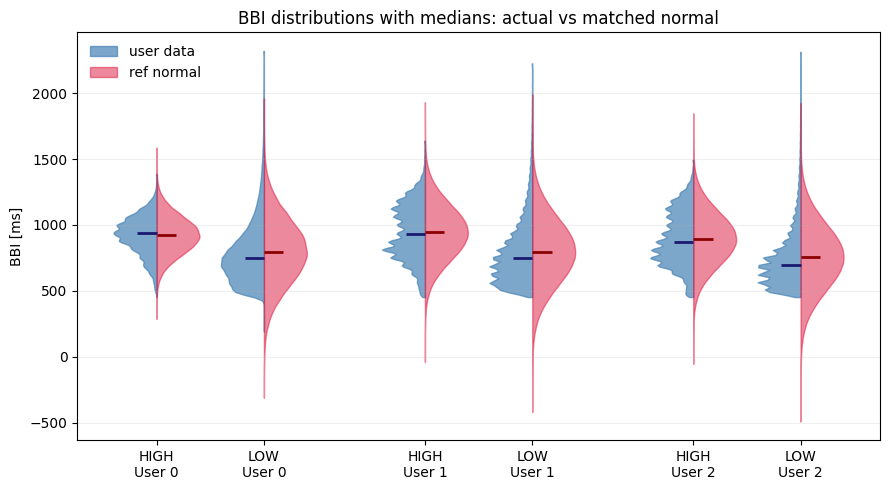

In [16]:
# half-violin comparison:
# left half  = actual BBI distribution
# right half = matched normal with sample mean/std

#q99 = df['BBI (ms)'].quantile(0.995)
plot_df = df.copy()
plot_df['BBI (ms)'] = (df.groupby(['User Id', 'Status'])['BBI (ms)'].transform(lambda s: s.clip(upper=s.quantile(0.999))))


fig, ax = plt.subplots(figsize=(9, 5))

labels = []
positions = []
pos = 1

for user in sorted(plot_df['User Id'].unique()):
    for status in sorted(plot_df['Status'].unique()):
        s = plot_df.loc[(plot_df['User Id'] == user) & (plot_df['Status'] == status), 'BBI (ms)'].to_numpy()
        normal_ref = scipy.stats.norm.rvs(loc=s.mean(), scale=s.std(ddof=1), size=s.shape[0], random_state=1)

        v_actual = ax.violinplot([s], positions=[pos], widths=0.8, showextrema=False)
        v_normal = ax.violinplot([normal_ref], positions=[pos], widths=0.8, showextrema=False)

        # keep only left half for actual data
        body_actual = v_actual['bodies'][0]
        verts = body_actual.get_paths()[0].vertices
        verts[:, 0] = np.minimum(verts[:, 0], pos)
        body_actual.set_facecolor('steelblue')
        body_actual.set_edgecolor('steelblue')
        body_actual.set_alpha(0.7)

        # keep only right half for matched normal
        body_normal = v_normal['bodies'][0]
        verts = body_normal.get_paths()[0].vertices
        verts[:, 0] = np.maximum(verts[:, 0], pos)
        body_normal.set_facecolor('crimson')
        body_normal.set_edgecolor('crimson')
        body_normal.set_alpha(0.5)

        # median lines
        med_actual = np.median(s)
        med_normal = np.median(normal_ref)
        ax.hlines(med_actual, pos - 0.18, pos, color='midnightblue', lw=2)
        ax.hlines(med_normal, pos, pos + 0.18, color='darkred', lw=2)

        labels.append(f'{status.split('_')[0]}\nUser {user}')
        positions.append(pos)
        pos += 1

    pos += 0.5

ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_ylabel('BBI [ms]')
ax.set_title('BBI distributions with medians: actual vs matched normal')
ax.grid(axis='y', alpha=0.2)

legend_handles = [
    Patch(facecolor='steelblue', edgecolor='steelblue', alpha=0.7, label='user data'),
    Patch(facecolor='crimson', edgecolor='crimson', alpha=0.5, label='ref normal'),
]
ax.legend(handles=legend_handles, frameon=False)

plt.tight_layout()
plt.show()


Text(0, 0.5, 'BBI [ms]')

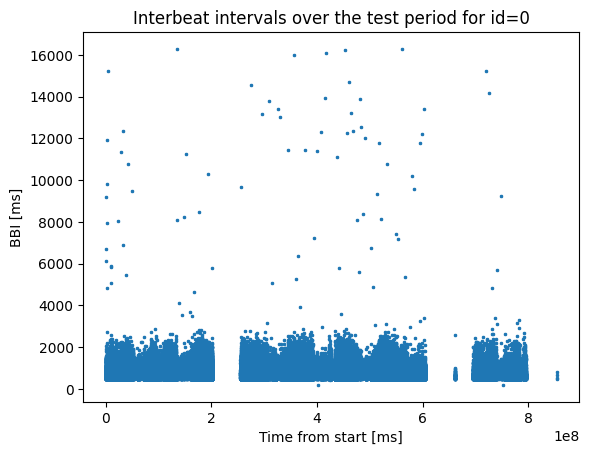

In [17]:
# lets look at a single user and show their measurements, x-axis is ms from the start of the analysis
user=0

temp=df.loc[df['User Id']==user,:]
x=temp['timeLocal_ms']-temp['timeLocal_ms'].min() 
y=temp['BBI (ms)']

fig,ax=plt.subplots()
ax.scatter(x=x, y=y, marker='x', s=3)
ax.set_title(f'Interbeat intervals over the test period for id={user}')
ax.set_xlabel('Time from start [ms]')
ax.set_ylabel('BBI [ms]') 

# clearly ms is a shitty resolution + there are a few outliers that make BBI values squished

(450.0, 1250.0)

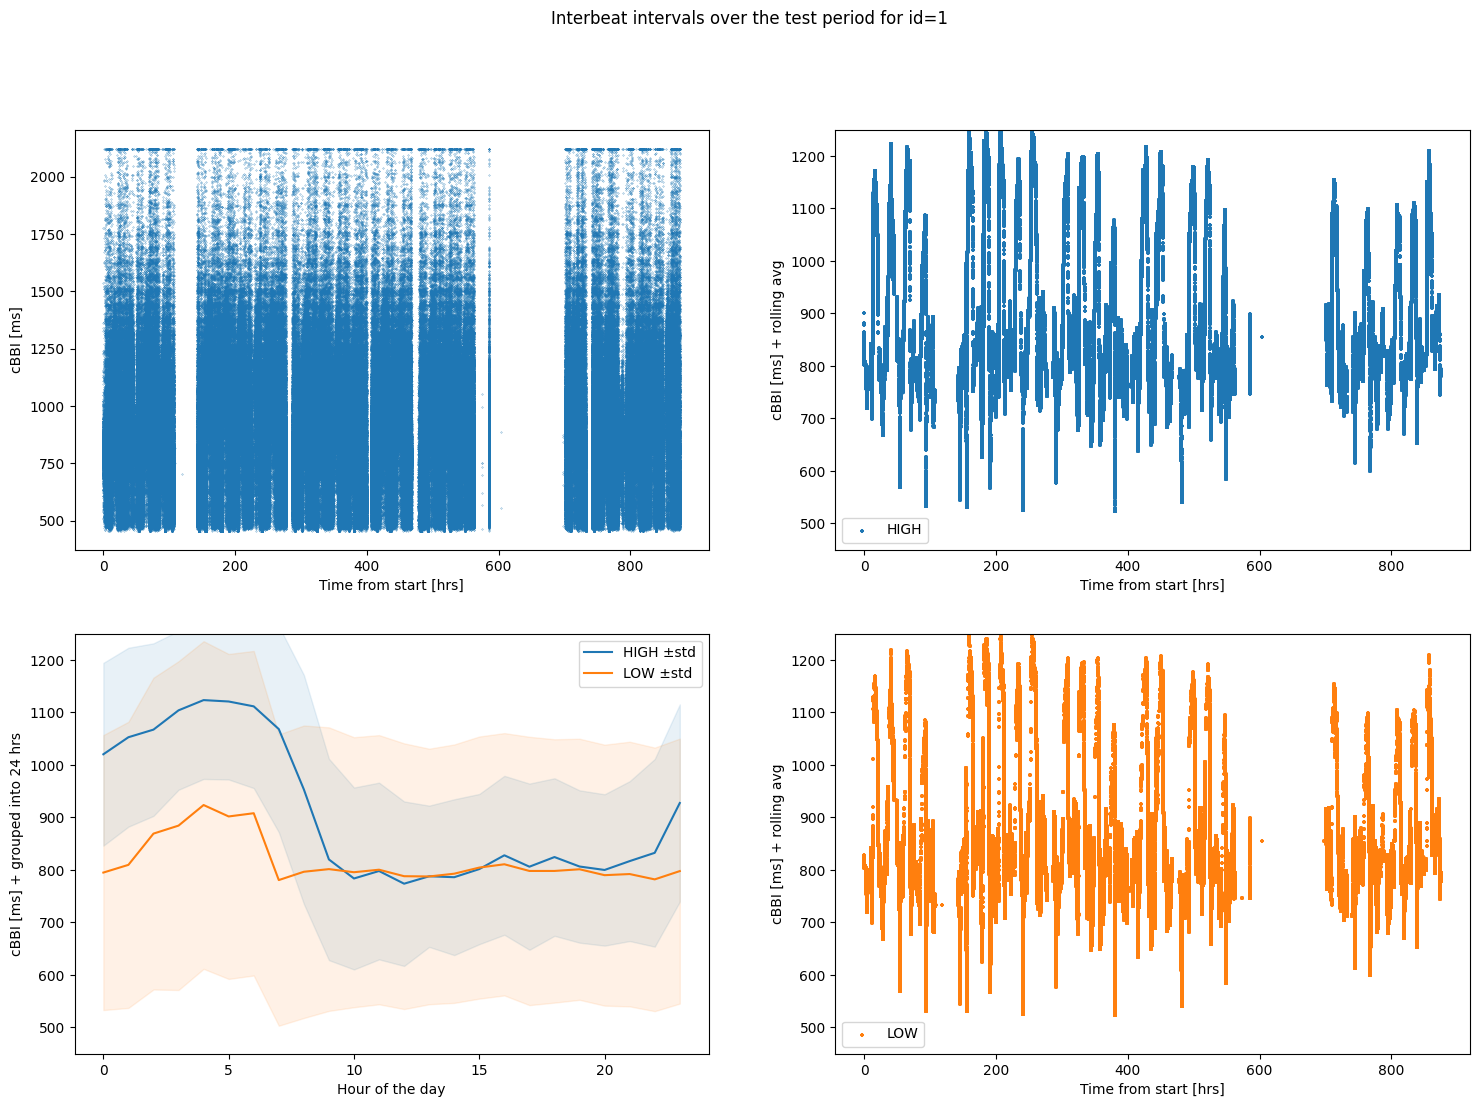

In [18]:
# winsorize, moving average, and groupby time of day for a single user
user=1
upper_clip=0.999 # very modest 
w=3_000 # do rolling average over w window

fig,ax=plt.subplots(nrows=2, ncols=2, figsize=(18,12))
fig.suptitle(f'Interbeat intervals over the test period for id={user}')
temp=df.loc[df['User Id']==user,:]

# Plot 1. clipped, no other processing
x=pd.to_timedelta(temp['timeLocal_ms']-temp['timeLocal_ms'].min(), unit='ms').dt.total_seconds() /3600 # let's change x to better unit, eg hours?
q_h=temp['BBI (ms)'].quantile(upper_clip) 
q_l=temp['BBI (ms)'].quantile(1-upper_clip) 
y=temp['BBI (ms)'].clip(upper=q_h, lower=q_l)
ax[0,0].scatter(x=x, y=y, s=.05)
ax[0,0].set_xlabel('Time from start [hrs]')
ax[0,0].set_ylabel('cBBI [ms]')

# Plots 2&4. clipped + moving average
y=y.rolling(window=w, min_periods=1).mean()
for status in ['HIGH_CONFIDENCE', 'LOW_CONFIDENCE']:
    mask=temp['Status'] == status
    if status=='HIGH_CONFIDENCE': 
        a=ax[0,1] 
        c='tab:blue'
    else: 
        a=ax[1,1]
        c='tab:orange'
    a.scatter(x=x[mask], y=y[mask], label=status.split('_')[0], marker='+', s=5, c=c)
    a.legend()
    a.set_xlabel('Time from start [hrs]')
    a.set_ylabel('cBBI [ms] + rolling avg') 
    a.set_ylim((450,1250))
    

# Plot 3. groupby [hour_of_day, status], then clip. Add CIs
hr=pd.to_datetime(temp['timeLocal_ms'], unit='ms').dt.hour
y=temp.groupby([hr, 'Status'])['BBI (ms)'].agg(
    lambda s: np.mean(s.clip(upper=q_h, lower=q_l))
    ).unstack('Status')
y_int=temp.groupby([hr, 'Status'])['BBI (ms)'].agg(
    lambda s: np.std(s.clip(upper=q_h, lower=q_l))
    ).unstack('Status')

for status in y.columns:
    if status=='HIGH_CONFIDENCE': c='tab:blue'
    else: c='tab:orange'
    ax[1,0].plot(y.index, y[status], label=status.split('_')[0]+' ±std')
    ax[1,0].fill_between(y.index, y[status]-y_int[status], y[status]+y_int[status], color=c, alpha=0.1)
ax[1,0].legend()    
ax[1,0].set_ylabel('cBBI [ms] + grouped into 24 hrs') 
ax[1,0].set_xlabel('Hour of the day')
ax[1,0].set_ylim((450,1250))


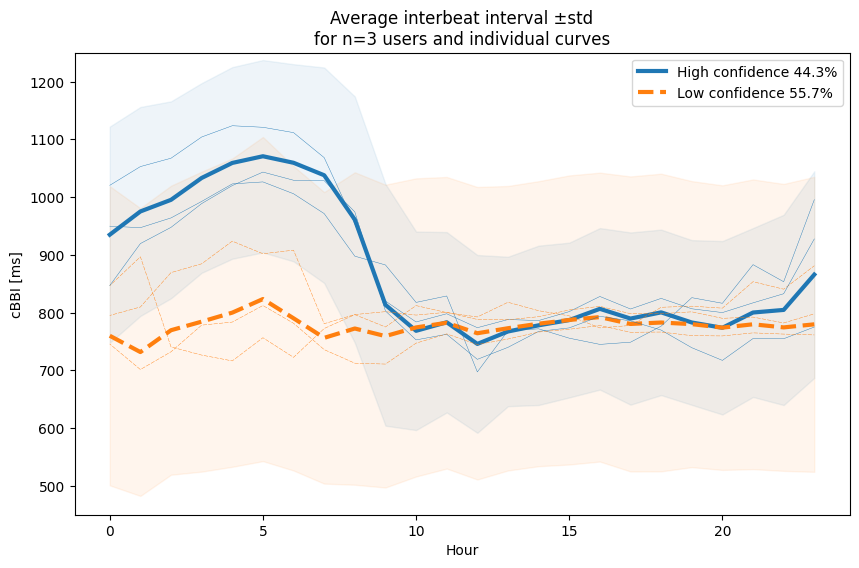

In [19]:
# lets do all users
upper_clip=0.999
fig,ax=plt.subplots(nrows=1, ncols=1, figsize=(10,6))
hr=pd.to_datetime(df['timeLocal_ms'], unit='ms').dt.hour 
counts=round((100*df.groupby('Status').size()/len(df)), 1).to_dict()

y=df.groupby([hr, 'Status'])['BBI (ms)']\
    .agg(lambda s: np.mean(s.clip(upper=q_h, lower=q_l))).unstack('Status')
y_int=df.groupby([hr, 'Status'])['BBI (ms)']\
    .agg(lambda s: np.std(s.clip(upper=q_h, lower=q_l))).unstack('Status')

ax.plot(y.index, y['HIGH_CONFIDENCE'], linewidth=3, linestyle='solid', c='tab:blue', label=f'High confidence {counts.get('HIGH_CONFIDENCE')}%')
ax.plot(y.index, y['LOW_CONFIDENCE'], linewidth=3, linestyle='dashed', c='tab:orange', label=f'Low confidence {counts.get('LOW_CONFIDENCE')}%')
ax.fill_between(y.index, y['HIGH_CONFIDENCE']-y_int['HIGH_CONFIDENCE'], y['HIGH_CONFIDENCE']+y_int['HIGH_CONFIDENCE'], color='tab:blue', alpha=0.075)
ax.fill_between(y.index, y['LOW_CONFIDENCE']-y_int['LOW_CONFIDENCE'], y['LOW_CONFIDENCE']+y_int['LOW_CONFIDENCE'], color='tab:orange', alpha=0.075)

# plot individual user lines
for user in df['User Id'].drop_duplicates():
    temp=df.loc[df['User Id']==user, :]
    q_h=temp['BBI (ms)'].quantile(upper_clip)
    q_l=temp['BBI (ms)'].quantile(1-upper_clip)

    y=temp.groupby([hr[temp.index], 'Status'])['BBI (ms)']\
        .agg(lambda s: np.mean(s.clip(upper=q_h, lower=q_l))).unstack('Status')
    for status in y.columns:
        if status=='HIGH_CONFIDENCE': 
            linestyle='solid'
            c='tab:blue'
        else: 
            linestyle=(5, (10, 3))
            c='tab:orange'
        ax.plot(y.index, y[status], linewidth=0.3, linestyle=linestyle, c=c)


ax.legend()    
ax.set_ylabel('cBBI [ms]') 
ax.set_xlabel('Hour') 
ax.set_ylim((450,1250))
ax.set_title(f'Average interbeat interval ±std\nfor n={df['User Id'].nunique()} users and individual curves')
plt.savefig('low_vs_high 27.02.2026-15.04.2026 data.png')


In [20]:
hr=pd.to_datetime(df['timeLocal_ms'], unit='ms').dt.hour 
gr=df.groupby([hr, 'Status'])['BBI (ms)'].size().unstack('Status')
sums=gr['HIGH_CONFIDENCE']+gr['LOW_CONFIDENCE']
gr.loc[:, 'HIGH_CONFIDENCE%']=round(100*gr['HIGH_CONFIDENCE']/sums, 2)
gr.loc[:, 'LOW_CONFIDENCE%']=round(100*gr['LOW_CONFIDENCE']/sums, 2)
gr



Status,HIGH_CONFIDENCE,LOW_CONFIDENCE,HIGH_CONFIDENCE%,LOW_CONFIDENCE%
timeLocal_ms,,,,
0,163156,107231,60.34,39.66
1,192378,56514,77.29,22.71
2,199978,31204,86.50,13.50
3,196387,25569,88.48,11.52
4,193877,24116,88.94,11.06
5,192200,22465,89.53,10.47
6,183039,36799,83.26,16.74
7,171146,54688,75.78,24.22
8,146099,95424,60.49,39.51


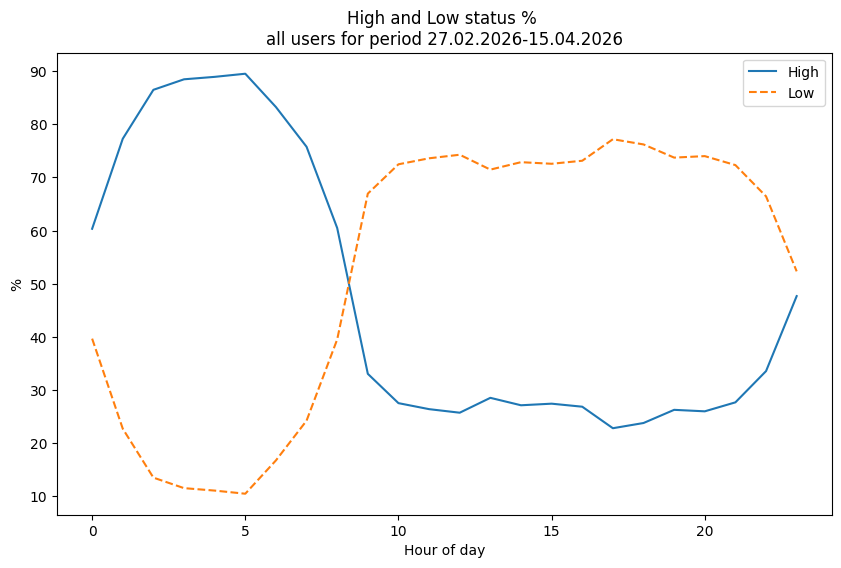

In [21]:
fig,ax=plt.subplots(nrows=1, ncols=1, figsize=(10,6))
ax.plot(gr.index, gr['HIGH_CONFIDENCE%'], linestyle='solid', label='High', c='tab:blue')
ax.plot(gr.index, gr['LOW_CONFIDENCE%'], linestyle='dashed', label='Low', c='tab:orange')
ax.legend()
ax.set_ylabel('%') 
ax.set_xlabel('Hour of day') 
ax.set_title(f'High and Low status % \nall users for period 27.02.2026-15.04.2026')
plt.savefig('low_vs_high fraction 27.02.2026-15.04.2026 data.png')


### HRV calculations